## Comparison between Trump and Obama speeches

In [1]:
#load the two datasets
from pathlib import Path
import pandas as pd

data_dir = Path.cwd() / 'data'
file_path_obama = data_dir / 'ten_speeches_obama.csv'
file_path_trump = data_dir / 'ten_speeches_trump.csv'

obama = pd.read_csv(file_path_obama)
trump = pd.read_csv(file_path_trump)

#(sub 1.2 working with data)

In [2]:
#extract the relevant columns/data and change the order of the columns
trump = trump[['date', 'title','transcript', 'word_count', 'stop_word_count', 'non_stopwords']].copy()
#change order of columns
obama = obama[['date', 'title', 'transcript']]

#(sub 1.3 working with data)

In [3]:
#add 'word_count', 'stop_word_count', 'non_stopwords' to the obama dataset
from gensim.utils import simple_preprocess
from nltk.corpus import stopwords

#tokenize, lowercase, removes punctuation, count the words
obama['word_count'] = [
    len(simple_preprocess(speech, min_len=1, max_len=100))
    for speech in obama['transcript']]

#count the stopwords
stop_words = stopwords.words('english')
obama['stop_word_count'] = [
    len([word for word in simple_preprocess(speech, min_len=1, max_len=100)
         if word in stop_words])
    for speech in obama['transcript']]

#extract non_stopwords
obama['non_stopwords'] = [
    ' '.join([word for word in simple_preprocess(speech)
              if word not in stop_words])
    for speech in obama['transcript']]

#(workshop nlp, nlp_canvas.ipynb)

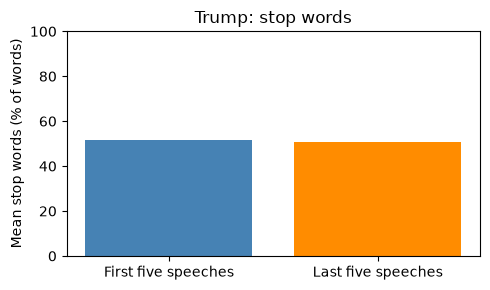

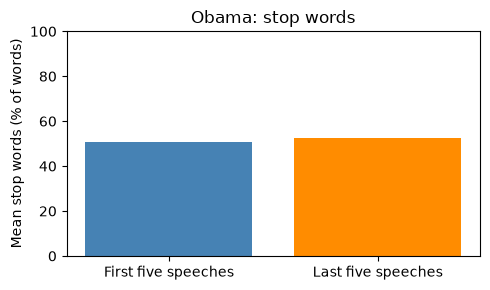

In [13]:
#visualize and compare speeches
import matplotlib.pyplot as plt

#calculate stopwords as a percentage of all words
trump['stop_word_rate'] = (trump['stop_word_count'] / trump['word_count'] * 100)
obama['stop_word_rate'] = (obama['stop_word_count'] / obama['word_count'] * 100)

#trumps first five vs last five speeches
trump_rates = [trump['stop_word_rate'].iloc[:5].mean(),
               trump['stop_word_rate'].iloc[-5:].mean()]

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['First five speeches', 'Last five speeches'],
       trump_rates,
       color=['steelblue', 'darkorange'])
ax.set_title('Trump: stop words')
ax.set_ylabel('Mean stop words (% of words)')
ax.set_ylim(0,100)
plt.tight_layout()
plt.show()

#obama first five vs last five speeches
obama_rates = [obama['stop_word_rate'].iloc[:5].mean(),
               obama['stop_word_rate'].iloc[-5:].mean()]

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['First five speeches', 'Last five speeches'],
       obama_rates,
       color=['steelblue', 'darkorange'])
ax.set_title('Obama: stop words')
ax.set_ylabel('Mean stop words (% of words)')
ax.set_ylim(0,100)
plt.tight_layout()
plt.show()

#(sub 1.4 visualisations)